In [ ]:
#步骤 1：将所有 CSV 文件合并成一个文件

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import os
import glob

# 根目录（就是 merge合并）
base_path = "/content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并"

#  关键：递归查找所有 CSV（包括子文件夹）
csv_files = glob.glob(os.path.join(base_path, "**", "*.csv"), recursive=True)

print("找到 CSV 文件数量：", len(csv_files))

df_list = []

for file_path in csv_files:
    print("读取：", file_path)

    try:
        try:
            df = pd.read_csv(file_path, encoding="utf-8-sig")
        except:
            try:
                df = pd.read_csv(file_path, encoding="utf-8")
            except:
                df = pd.read_csv(file_path, encoding="gb18030")

        df_list.append(df)

    except Exception as e:
        print(" 读取失败：", file_path)
        print(e)

# 合并
merged_df = pd.concat(df_list, ignore_index=True)

# 去重（推荐）
merged_df = merged_df.drop_duplicates(subset=["title", "content"])

# 保存
output_path = os.path.join(base_path, "merged_all_news.csv")
merged_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("\n 合并完成！")
print("总行数：", len(merged_df))
print("保存路径：", output_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
找到 CSV 文件数量： 785
读取： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/merged_all_news.csv
读取： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/Oriental Daily News/2016/oriental_daily_2016_1.csv
读取： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/Oriental Daily News/2016/oriental_daily_2016_2.csv
读取： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/Oriental Daily News/2016/oriental_daily_2016_3.csv
读取： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/Oriental Daily News/2016/oriental_daily_2016_4.csv
读取： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/Oriental Daily News/2016/oriental_daily_2016_5.csv
读取： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/Oriental Daily News/2016/oriental_daily_2016_6.csv
读取： /content/drive/MyDrive/Colab Noteb

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import os
import glob
import time
from tqdm import tqdm  #  进度条

# ⏱ 开始计时
start_time = time.time()

# 根目录
base_path = "/content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并"

# 递归查找 CSV
csv_files = glob.glob(os.path.join(base_path, "**", "*.csv"), recursive=True)

print("找到 CSV 文件数量：", len(csv_files))

df_list = []

#  tqdm 进度条
for file_path in tqdm(csv_files, desc="读取CSV文件"):

    try:
        try:
            df = pd.read_csv(file_path, encoding="utf-8-sig")
        except:
            try:
                df = pd.read_csv(file_path, encoding="utf-8")
            except:
                df = pd.read_csv(file_path, encoding="gb18030")

        df_list.append(df)

    except Exception as e:
        print(" 读取失败：", file_path)
        print(e)

# 合并
print("\n 正在合并数据...")
merged_df = pd.concat(df_list, ignore_index=True)

# 去重
merged_df = merged_df.drop_duplicates(subset=["title", "content"])

# 保存
output_path = os.path.join(base_path, "merged_all_news.csv")
merged_df.to_csv(output_path, index=False, encoding="utf-8-sig")

# 结束计时
end_time = time.time()
elapsed_time = end_time - start_time

print("\n 合并完成！")
print("总行数：", len(merged_df))
print("保存路径：", output_path)

# 显示耗时
print(f"\n⏱ 总耗时：{elapsed_time:.2f} 秒（约 {elapsed_time/60:.2f} 分钟）")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
找到 CSV 文件数量： 785


读取CSV文件:  59%|█████▊    | 460/785 [00:01<00:01, 290.74it/s]

 读取失败： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/Hongkong CD/2022/Hongkong_CD_2022_11.csv
'gb18030' codec can't decode byte 0x80 in position 69: illegal multibyte sequence
 读取失败： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/Hongkong CD/2022/Hongkong_CD_2022_15.csv
'gb18030' codec can't decode byte 0x80 in position 47: illegal multibyte sequence


读取CSV文件: 100%|██████████| 785/785 [00:03<00:00, 247.00it/s]



 正在合并数据...

 合并完成！
总行数： 732
保存路径： /content/drive/MyDrive/Colab Notebooks/JLAO 39/Data/Media/merge合并/merged_all_news.csv

⏱ 总耗时：3.44 秒（约 0.06 分钟）


#Token avec Jieba

In [ ]:
!pip install jieba

In [ ]:
import pandas as pd
import jieba
import time
from tqdm import tqdm

#  开始计时
start_time = time.time()

# 读取数据
file_path = "/content/merged_all_news.csv"
df = pd.read_csv(file_path)

print("总行数：", len(df))

# 激活 tqdm 在 pandas 中
tqdm.pandas(desc=" 分词中")

# 定义分词函数
def tokenize(text):
    if pd.isna(text):
        return ""
    return " ".join(jieba.cut(text))

# 使用 progress_apply（关键！！！）
df["content_token"] = df["content"].progress_apply(tokenize)

# 保存
output_path = file_path.replace(".csv", "_tokenized.csv")
df.to_csv(output_path, index=False, encoding="utf-8-sig")

#  结束计时
end_time = time.time()
elapsed = end_time - start_time

print("\n 分词完成：", output_path)
print(f" 总耗时：{elapsed:.2f} 秒（约 {elapsed/60:.2f} 分钟）")

/usr/local/lib/python3.12/dist-packages/jieba/__init__.py:44: SyntaxWarning: invalid escape sequence '\.'
  re_han_default = re.compile("([\u4E00-\u9FD5a-zA-Z0-9+#&\._%\-]+)", re.U)
/usr/local/lib/python3.12/dist-packages/jieba/__init__.py:46: SyntaxWarning: invalid escape sequence '\s'
  re_skip_default = re.compile("(\r\n|\s)", re.U)
/usr/local/lib/python3.12/dist-packages/jieba/finalseg/__init__.py:78: SyntaxWarning: invalid escape sequence '\.'
  re_skip = re.compile("([a-zA-Z0-9]+(?:\.\d+)?%?)")


总行数： 732


 分词中:   0%|          | 0/732 [00:00<?, ?it/s]Building prefix dict from the default dictionary ...
DEBUG:jieba:Building prefix dict from the default dictionary ...
Dumping model to file cache /tmp/jieba.cache
DEBUG:jieba:Dumping model to file cache /tmp/jieba.cache
Loading model cost 0.740 seconds.
DEBUG:jieba:Loading model cost 0.740 seconds.
Prefix dict has been built successfully.
DEBUG:jieba:Prefix dict has been built successfully.
 分词中: 100%|██████████| 732/732 [00:09<00:00, 75.80it/s]



 分词完成： /content/merged_all_news_tokenized.csv
 总耗时：9.77 秒（约 0.16 分钟）


#1） Identification new forms （有PMI）

In [ ]:
#Step 1 — 读取数据

import pandas as pd
import numpy as np
import unicodedata
import re
import math
from collections import Counter, defaultdict

IN_REF = "/content/cccanto_words_39988.txt"
IN_CORPUS = "/content/merged_all_news_tokenized.csv"

def normalize(s):
    return unicodedata.normalize("NFKC", str(s)).strip()

ref_set = set()

with open(IN_REF, encoding="utf-8") as f:
    for line in f:
        w = normalize(line)
        if w:
            ref_set.add(w)

df = pd.read_csv(IN_CORPUS)

df["content"] = df["content"].fillna("").astype(str).map(normalize)
df["date_parsed"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date_parsed"].dt.year

print("参考词表数量:", len(ref_set))
print("语料文章数:", len(df))
print(df["year"].value_counts().sort_index())

参考词表数量: 39988
语料文章数: 732
year
2016.0    25
2017.0    44
2018.0    46
2019.0    50
2020.0    38
2021.0    31
2022.0    21
2023.0    20
2024.0    20
2025.0    21
2026.0    42
Name: count, dtype: int64


/tmp/ipykernel_16149/3382346813.py:27: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date_parsed"] = pd.to_datetime(df["date"], errors="coerce")
/tmp/ipykernel_16149/3382346813.py:27: FutureWarning: Parsed string "03:00 2020-12-07 HKT" included an un-recognized timezone "HKT". Dropping unrecognized timezones is deprecated; in a future version this will raise. Instead pass the string without the timezone, then use .tz_localize to convert to a recognized timezone.
  df["date_parsed"] = pd.to_datetime(df["date"], errors="coerce")
/tmp/ipykernel_16149/3382346813.py:27: FutureWarning: Parsed string "03:00 2020-12-12 HKT" included an un-recognized timezone "HKT". Dropping unrecognized timezones is deprecated; in a future version this will raise. Instead pass the string without the timezone, then use .tz_localize to convert to a recognized timezone.
 

In [ ]:
#Step 2 — 字符过滤

VALID_CHAR = re.compile(r"[A-Za-z0-9\u4e00-\u9fff]")

def is_valid_char(ch):
    return bool(VALID_CHAR.fullmatch(ch))

In [ ]:
#Step 3 — 候选形式分类

NUMERIC_NEOLOGISM_WHITELIST = {
    "996", "520", "886", "233", "1314"
}

OLD_WORD_BLACKLIST = {
    "美國", "香港", "中國", "日本", "台灣",
    "政府", "經濟", "發展", "文化", "科技",
    "社會", "政策", "活動", "方面", "表示",
    "開始", "沒有", "未來", "時間", "第一",
    "美元", "旅遊"
}

NAMED_ENTITY_BLACKLIST = {
    "川普", "拜登", "特朗普",
    "大紀元", "大紀", "紀元",
    "東方日報", "香港商報"
}

STOP_BOUNDARY = {
    "的", "了", "在", "是", "和",
    "嘅", "咗", "喺", "係", "同",
    "都", "就", "又", "而家", "呢",
    "啦", "呀", "啊", "嗎", "么",
    "及", "與", "或", "並", "且"
}

def bad_boundary(term):
    term = str(term).strip()
    for sw in STOP_BOUNDARY:
        if term.startswith(sw) or term.endswith(sw):
            return True
    return False

def classify_candidate(term):
    term = str(term).strip()

    if not term:
        return "reject_empty"

    if bad_boundary(term):
        return "reject_bad_boundary"

    if term in OLD_WORD_BLACKLIST:
        return "reject_old_word"

    if term in NAMED_ENTITY_BLACKLIST:
        return "reject_named_entity"

    if len(set(term)) == 1:
        return "reject_repetition"

    # 纯数字：只保留白名单
    if re.fullmatch(r"[0-9]{2,5}", term):
        if term in NUMERIC_NEOLOGISM_WHITELIST:
            return "numeric_neologism"
        return "reject_number_noise"

    # 年月日期残片
    if re.fullmatch(r"20[0-9]{1,2}", term):
        return "reject_year_fragment"

    if re.fullmatch(r"[0-9]{1,2}月", term):
        return "reject_date_fragment"

    if re.fullmatch(r"[0-9]{2}年", term):
        return "reject_date_fragment"

    if re.fullmatch(r"20[0-9]{2}年", term):
        return "reject_date_fragment"

    # 中文词
    if re.fullmatch(r"[\u4e00-\u9fff]{2,6}", term):
        return "chinese_candidate"

    # AI / NFT / KOL / COVID
    if re.fullmatch(r"[A-Z]{2,10}", term):
        return "acronym_candidate"

    # 90後 / 00後 / 996制
    if re.fullmatch(r"[0-9]{2,4}[\u4e00-\u9fff]{1,2}", term):
        return "numeric_chinese_candidate"

    # AI生成 / Web3經濟 / COVID疫情
    if re.fullmatch(r"[A-Za-z0-9]{2,15}[\u4e00-\u9fff]{1,4}", term):
        return "mixed_candidate"

    # 生成AI / 港版NFT
    if re.fullmatch(r"[\u4e00-\u9fff]{1,4}[A-Za-z0-9]{2,15}", term):
        return "mixed_candidate"

    return "reject_other"

def is_good_form(term):
    label = classify_candidate(term)
    return label in {
        "chinese_candidate",
        "acronym_candidate",
        "numeric_neologism",
        "numeric_chinese_candidate",
        "mixed_candidate"
    }

In [ ]:
#Step 4 — 分句

SENT_SEP = set("。！？!?；;：:\n\r")

def to_char_list(text):
    chars = []
    for ch in text:
        if ch in SENT_SEP:
            chars.append(ch)
        elif is_valid_char(ch):
            chars.append(ch)
    return chars

def split_sent(chars):
    sents = []
    cur = []

    for ch in chars:
        cur.append(ch)
        if ch in SENT_SEP:
            sents.append(cur)
            cur = []

    if cur:
        sents.append(cur)

    return sents

In [ ]:
#Step 5 — 2–6 字符滑窗

N_RANGE = range(2, 7)

freq = {n: Counter() for n in N_RANGE}
dfreq = {n: Counter() for n in N_RANGE}
first_year = {n: {} for n in N_RANGE}
candidate_type = {}

for _, row in df.iterrows():
    year = row["year"]
    text = row["content"]

    chars = to_char_list(text)
    sents = split_sent(chars)

    seen_doc = {n: set() for n in N_RANGE}

    for sent in sents:
        clean = [c for c in sent if c not in SENT_SEP]

        for n in N_RANGE:
            for i in range(len(clean) - n + 1):
                cand = "".join(clean[i:i+n])

                if cand in ref_set:
                    continue

                ctype = classify_candidate(cand)

                if not is_good_form(cand):
                    continue

                freq[n][cand] += 1
                seen_doc[n].add(cand)
                candidate_type[cand] = ctype

    for n in N_RANGE:
        for w in seen_doc[n]:
            dfreq[n][w] += 1
            if w not in first_year[n] and not pd.isna(year):
                first_year[n][w] = int(year)

In [ ]:
# Step 6 — 输出初步形式候选词

def build_df(n):
    rows = []

    for w, f in freq[n].items():
        rows.append({
            "term": w,
            "len": n,
            "freq": f,
            "doc_freq": dfreq[n][w],
            "first_year": first_year[n].get(w),
            "candidate_type": candidate_type.get(w)
        })

    return pd.DataFrame(rows).sort_values(
        ["freq", "doc_freq"],
        ascending=False
    )

for n in N_RANGE:
    df_n = build_df(n)
    df_n.to_csv(
        f"/content/new_words_len{n}.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("初步形式候选词表已保存")

初步形式候选词表已保存


In [ ]:
#Step 7 — PMI + 正确左右熵

ngram_freq = {n: Counter() for n in N_RANGE}
uni_freq = Counter()

left_ctx = defaultdict(Counter)
right_ctx = defaultdict(Counter)

for text in df["content"]:
    chars = [c for c in text if is_valid_char(c)]
    uni_freq.update(chars)

    for n in N_RANGE:
        for i in range(len(chars) - n + 1):
            ng = "".join(chars[i:i+n])

            if ng in ref_set:
                continue

            if not is_good_form(ng):
                continue

            ngram_freq[n][ng] += 1

            if i > 0:
                left_ctx[ng][chars[i-1]] += 1

            if i + n < len(chars):
                right_ctx[ng][chars[i+n]] += 1

N = sum(uni_freq.values())

def PMI(ng, freq_ng):
    total_ng = sum(freq_ng.values())

    if total_ng == 0:
        return 0

    p_joint = freq_ng[ng] / total_ng

    p_indep = 1
    for ch in ng:
        if uni_freq[ch] == 0:
            return 0
        p_indep *= uni_freq[ch] / N

    return math.log(p_joint / (p_indep + 1e-12))

def entropy(counter):
    total = sum(counter.values())

    if total == 0:
        return 0

    return -sum(
        (c / total) * math.log(c / total + 1e-12)
        for c in counter.values()
    )

def lr_entropy(ng):
    return entropy(left_ctx[ng]) + entropy(right_ctx[ng])

In [ ]:
#Step 8 — 最终过滤

MIN_FREQ = 5
MIN_DOC_FREQ = 2
MIN_PMI = 3
MIN_ENTROPY = 2

candidates = []

for n in N_RANGE:
    for ng, f in ngram_freq[n].items():

        if f < MIN_FREQ:
            continue

        if dfreq[n].get(ng, 0) < MIN_DOC_FREQ:
            continue

        if ng in ref_set:
            continue

        if not is_good_form(ng):
            continue

        pmi = PMI(ng, ngram_freq[n])
        ent = lr_entropy(ng)
        ctype = classify_candidate(ng)

        if pmi >= MIN_PMI and ent >= MIN_ENTROPY:
            candidates.append({
                "term": ng,
                "len": n,
                "freq": f,
                "doc_freq": dfreq[n].get(ng, 0),
                "first_year": first_year[n].get(ng),
                "candidate_type": ctype,
                "PMI": pmi,
                "entropy": ent
            })

df_out = pd.DataFrame(candidates)

df_out = df_out.sort_values(
    ["candidate_type", "freq", "doc_freq", "PMI", "entropy"],
    ascending=[True, False, False, False, False]
).reset_index(drop=True)

df_out.to_csv(
    "/content/candidates_form_neologisms.csv",
    index=False,
    encoding="utf-8-sig"
)

print("最终候选新词数量:", len(df_out))
print(df_out["candidate_type"].value_counts())
print(df_out.head(50))

最终候选新词数量: 14426
candidate_type
chinese_candidate            12977
mixed_candidate                684
numeric_chinese_candidate      457
acronym_candidate              305
numeric_neologism                3
Name: count, dtype: int64
   term  len  freq  doc_freq  first_year     candidate_type        PMI  \
0    AI    2   100        31      2026.0  acronym_candidate   5.138846   
1    DP    2    93        43      2017.0  acronym_candidate   5.659649   
2    GD    2    88        39      2017.0  acronym_candidate   6.229828   
3   GDP    3    87        38      2017.0  acronym_candidate  12.837382   
4    CE    2    75        29      2017.0  acronym_candidate   5.029566   
5    EC    2    69        30      2016.0  acronym_candidate   4.946184   
6    PE    2    68        26      2021.0  acronym_candidate   5.093984   
7    IP    2    59        25      2019.0  acronym_candidate   4.830485   
8    AP    2    58        36      2026.0  acronym_candidate   4.520197   
9    LA    2    57        20

In [ ]:
# Step 9 — 正确左右熵

def entropy(counter):

    total = sum(counter.values())

    if total == 0:
        return 0

    return -sum(
        (c / total) * math.log(c / total + 1e-12)
        for c in counter.values()
    )


def lr_entropy(ng):
    return entropy(left_ctx[ng]) + entropy(right_ctx[ng])

In [ ]:
# Step 10 — 最终过滤候选新词

MIN_FREQ = 5
MIN_DOC_FREQ = 2
MIN_PMI = 3
MIN_ENTROPY = 2

candidates = []

for n in N_RANGE:

    for ng, f in ngram_freq[n].items():

        if f < MIN_FREQ:
            continue

        if dfreq[n].get(ng, 0) < MIN_DOC_FREQ:
            continue

        if ng in ref_set:
            continue

        if not is_good_form(ng):
            continue

        pmi = PMI(ng, ngram_freq[n])
        ent = lr_entropy(ng)

        if pmi >= MIN_PMI and ent >= MIN_ENTROPY:

            candidates.append({
                "term": ng,
                "len": n,
                "freq": f,
                "doc_freq": dfreq[n].get(ng, 0),
                "first_year": first_year[n].get(ng),
                "PMI": pmi,
                "entropy": ent
            })


df_out = pd.DataFrame(candidates)

df_out = df_out.sort_values(
    ["freq", "doc_freq", "PMI", "entropy"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

df_out.to_csv(
    "/content/candidates_form_neologisms.csv",
    index=False,
    encoding="utf-8-sig"
)

print("最终候选新词数量:", len(df_out))
print(df_out.head(50))

最终候选新词数量: 14426
    term  len  freq  doc_freq  first_year        PMI   entropy
0     一個    2   796       254      2020.0   4.209747  9.394302
1     疫情    2   435       120      2020.0   6.603519  9.020072
2     發生    2   390       127      2020.0   4.457319  8.550228
3     貿易    2   384        88      2017.0   7.403582  7.895953
4     產業    2   383        88      2018.0   4.830686  8.957997
5    億美元    3   346        77      2017.0  10.454809  6.639752
6     億美    2   346        77      2017.0   4.898820  2.258078
7   017年    4   343       105      2017.0  11.421920  4.290357
8     預言    2   331        29      2026.0   6.221466  8.080848
9     歷史    2   328       144      2020.0   7.456787  7.696850
10    超過    2   322       174      2017.0   5.906408  7.565322
11  024年    4   322        80      2026.0  10.976318  4.216619
12    認為    2   320       160      2017.0   5.433938  8.684407
13    記者    2   318       250      2019.0   6.242912  7.121169
14    這些    2   316       147      2017

#语义

In [ ]:
# Step 0 — 安装库

!pip install -q pandas numpy sentence-transformers scikit-learn tqdm

In [ ]:
# Step 1 — 导入库

import pandas as pd
import numpy as np
import re
import unicodedata
import warnings
import torch

from tqdm import tqdm
from collections import defaultdict

from sentence_transformers import SentenceTransformer
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")

In [ ]:
# Step 2 — 路径设置

CORPUS_PATH = "/content/merged_all_news_tokenized.csv"

# 这里用已经生成好的形式候选词表
CANDIDATE_PATH = "/content/candidates_form_neologisms.csv"

OUT_SUMMARY = "/content/semantic_summary_cantonese.csv"
OUT_YEARLY = "/content/semantic_shift_by_year_cantonese.csv"
OUT_CONTEXTS = "/content/semantic_contexts_cantonese.csv"

In [ ]:
# Step 3 — 文本清洗函数

def normalize_text(s: str) -> str:
    s = unicodedata.normalize("NFKC", str(s))
    s = s.replace("\u3000", " ").replace("\xa0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s


def detokenize_chinese_text(s: str) -> str:
    s = normalize_text(s)

    # 中文之间去空格
    s = re.sub(r"(?<=[\u4e00-\u9fff])\s+(?=[\u4e00-\u9fff])", "", s)

    # 中文和标点之间去空格
    s = re.sub(r"(?<=[\u4e00-\u9fff])\s+([，。！？；：、“”‘’（）《》])", r"\1", s)
    s = re.sub(r"([，。！？；：、“”‘’（）《》])\s+(?=[\u4e00-\u9fff])", r"\1", s)

    return s.strip()

In [ ]:
# Step 4 — 读取语料

corpus = pd.read_csv(
    CORPUS_PATH,
    engine="python",
    on_bad_lines="skip"
)

corpus.columns = corpus.columns.str.strip()

TEXT_CANDIDATES = ["content", "text", "sentence", "corpus"]
DATE_CANDIDATES = ["date", "time", "year", "publish_date", "pub_date"]

text_col = None
for c in TEXT_CANDIDATES:
    if c in corpus.columns:
        text_col = c
        break

if text_col is None:
    raise ValueError("没有找到文本列，请检查 content/text/sentence/corpus")

date_col = None
for c in DATE_CANDIDATES:
    if c in corpus.columns:
        date_col = c
        break

if date_col is None:
    raise ValueError("没有找到日期列，请检查 date/time/year/publish_date/pub_date")

corpus[text_col] = corpus[text_col].fillna("").astype(str).map(detokenize_chinese_text)

print("语料条数:", len(corpus))
print("文本列:", text_col)
print("日期列:", date_col)

语料条数: 732
文本列: content
日期列: date


In [ ]:
# Step 5 — 提取年份

def extract_year(x):
    if pd.isna(x):
        return np.nan

    x = str(x)
    m = re.search(r"(20\d{2}|19\d{2})", x)

    if m:
        return int(m.group(1))

    return np.nan


corpus["year"] = corpus[date_col].apply(extract_year)

corpus = corpus[
    (corpus["year"] >= 2016) &
    (corpus["year"] <= 2026)
].copy()

print("过滤后语料条数:", len(corpus))
print(corpus["year"].value_counts().sort_index())

过滤后语料条数: 698
year
2016.0    68
2017.0    73
2018.0    69
2019.0    68
2020.0    50
2021.0    52
2022.0    47
2023.0    64
2024.0    65
2025.0    72
2026.0    70
Name: count, dtype: int64


In [ ]:
# ============================================================
# Step 6 — 读取并严格筛选新词候选词
# ============================================================

def classify_form_type(term):
    term = str(term).strip()

    if re.fullmatch(r"[\u4e00-\u9fff]{2,8}", term):
        return "chinese_only"

    if re.fullmatch(r"[A-Z]{2,10}", term):
        return "acronym"

    if re.fullmatch(r"[0-9]{2,4}", term):
        return "numeric"

    if re.fullmatch(r"[0-9]{2,4}[\u4e00-\u9fff]{1,3}", term):
        return "numeric_chinese"

    if re.fullmatch(r"[A-Za-z0-9]{2,15}[\u4e00-\u9fff]{1,6}", term):
        return "mixed"

    if re.fullmatch(r"[\u4e00-\u9fff]{1,6}[A-Za-z0-9]{2,15}", term):
        return "mixed"

    return "other"


COMMON_WORDS = {
    "超過", "繼續", "支持", "研究", "這個", "服務", "生活", "更多",
    "記者", "政治", "歷史", "組織", "數據", "關注", "計劃", "公布",
    "許多", "需要", "最後", "產品", "預計", "時代", "進入", "舉行",
    "相關", "根據", "期間", "首次", "最高", "特別", "總統", "新聞",
    "認為", "通過", "重要", "這些", "提供", "發生", "這一", "自己",
    "最大", "部分", "過去", "目前", "一步", "顯示", "獲得", "還有",
    "變化", "領域", "產業", "項目", "金融", "貿易", "推動", "工作",
    "問題", "社會", "政府", "中國", "香港", "美國", "世界", "公司",
    "市場", "發展", "國家", "時間", "包括", "可以", "可能", "如果",
    "今日", "昨日", "今年", "去年", "人士", "方面", "情況", "進一步"
}

BAD_PATTERNS = [
    r"^\d+$",
    r"^\d+月$",
    r"^\d+日$",
    r"^20\d{2}$",
    r"^20\d{2}年$",
    r"^年\d+$",
    r"^第[一二三四五六七八九十\d]+$",
    r".*記者$",
    r".*日訊$",
    r".*大紀元.*",
    r".*億元?$",
    r".*億美元$",
    r"^[A-Z]{2,4}$"
]


IMPORTANT_NEOLOGISMS = {
    "新冠", "新冠疫情", "動態清零", "修例風波", "國安法",
    "元宇宙", "ChatGPT", "NFT", "KOL", "Web3", "區塊鏈",
    "生成式AI", "人工智能", "直播帶貨", "躺平", "內卷",
    "996", "00後", "90後"
}


def is_bad_pattern(term):
    term = str(term).strip()
    return any(re.fullmatch(p, term) for p in BAD_PATTERNS)


def load_candidate_words_strict(path, top_n=None):
    cand_df = pd.read_csv(path)
    cand_df.columns = cand_df.columns.str.strip()

    if "term" not in cand_df.columns:
        raise ValueError("候选词表中没有 term 列")

    cand_df["term"] = cand_df["term"].astype(str).str.strip()
    cand_df = cand_df[cand_df["term"] != ""].drop_duplicates("term").copy()

    cand_df["form_type"] = cand_df["term"].apply(classify_form_type)

    KEEP_TYPES = {
        "chinese_only",
        "acronym",
        "mixed",
        "numeric_chinese"
    }

    cand_df = cand_df[cand_df["form_type"].isin(KEEP_TYPES)].copy()

    cand_df = cand_df[~cand_df["term"].isin(COMMON_WORDS)].copy()
    cand_df = cand_df[~cand_df["term"].apply(is_bad_pattern)].copy()

    if "freq" in cand_df.columns:
        cand_df = cand_df.sort_values("freq", ascending=False)

    if top_n is not None:
        cand_df = cand_df.head(top_n)

    # 强制加入你关心的新词
    extra_df = pd.DataFrame({
        "term": list(IMPORTANT_NEOLOGISMS),
        "form_type": ["manual"] * len(IMPORTANT_NEOLOGISMS)
    })

    cand_df = pd.concat(
        [cand_df[["term", "form_type"]], extra_df],
        ignore_index=True
    ).drop_duplicates("term")

    words = cand_df["term"].tolist()

    return words, cand_df


neo_words, candidate_df = load_candidate_words_strict(
    CANDIDATE_PATH,
    top_n=5000
)

print("严格过滤后的候选词数量:", len(neo_words))
print(candidate_df["form_type"].value_counts())
print(candidate_df.head(50))

严格过滤后的候选词数量: 5016
form_type
chinese_only       4682
mixed               191
numeric_chinese     119
manual               16
acronym               8
Name: count, dtype: int64
    term        form_type
0     一個     chinese_only
1     疫情     chinese_only
2     億美     chinese_only
3   017年  numeric_chinese
4     預言     chinese_only
5   024年  numeric_chinese
6   023年  numeric_chinese
7   018年  numeric_chinese
8   016年  numeric_chinese
9     進行     chinese_only
10  020年  numeric_chinese
11  025年  numeric_chinese
12    近平     chinese_only
13   習近平     chinese_only
14    習近     chinese_only
15  022年  numeric_chinese
16  021年  numeric_chinese
17    改革     chinese_only
18    英國     chinese_only
19    科學     chinese_only
20    消費     chinese_only
21  019年  numeric_chinese
22    智能     chinese_only
23    行業     chinese_only
24    選舉     chinese_only
25    病毒     chinese_only
26    收入     chinese_only
27    自由     chinese_only
28    預測     chinese_only
29    預期     chinese_only
30    聯合     chinese

In [ ]:
# ============================================================
# Step 7 — 再次过滤：只保留适合语义漂移分析的词
# ============================================================

def is_good_semantic_candidate(term):
    term = str(term).strip()

    if not term:
        return False

    if term in IMPORTANT_NEOLOGISMS:
        return True

    if term in COMMON_WORDS:
        return False

    if is_bad_pattern(term):
        return False

    # 纯中文词：要求 2–8 字
    if re.fullmatch(r"[\u4e00-\u9fff]{2,8}", term):
        return True

    # 英文缩写类：只保留比较明确的新词缩写
    if re.fullmatch(r"[A-Z]{2,10}", term):
        return term in {"AI", "NFT", "KOL", "COVID", "GPT", "ChatGPT"}

    # 数字 + 中文
    if re.fullmatch(r"[0-9]{2,4}[\u4e00-\u9fff]{1,3}", term):
        return True

    # 英文/数字 + 中文
    if re.fullmatch(r"[A-Za-z0-9]{2,15}[\u4e00-\u9fff]{1,6}", term):
        return True

    # 中文 + 英文/数字
    if re.fullmatch(r"[\u4e00-\u9fff]{1,6}[A-Za-z0-9]{2,15}", term):
        return True

    return False


neo_words = [w for w in neo_words if is_good_semantic_candidate(w)]

print("最终可做语义分析的候选词数:", len(neo_words))
print("前100个候选词:")
print(neo_words[:100])

print("检查新冠相关候选词:")
print([w for w in neo_words if "新冠" in w])

最终可做语义分析的候选词数: 5009
前100个候选词:
['一個', '疫情', '億美', '017年', '預言', '024年', '023年', '018年', '016年', '進行', '020年', '025年', '近平', '習近平', '習近', '022年', '021年', '改革', '英國', '科學', '消費', '019年', '智能', '行業', '選舉', '病毒', '收入', '自由', '預測', '預期', '聯合', '深圳', '加拿', '銀行', '電影', '會議', '房地', '萬人', '個月', '規模', '香港商', '聯儲', '026年', '環境', '國經濟', '財富', '製造', '推進', '目標', '歐洲', '月份', '股市', '羅斯', '舉辦', '進一', '造成', '重大', '表現', '提升', '關稅', '上升', '排名', '平台', '法輪', '非常', '綜合', '貨幣', '運動', '達到', '行政', '集團', '推出', '機會', '開放', '正式', '俄羅', '風險', '財政', '最佳', '看到', '日訊大', '資產', '行動', '元202', '日訊大紀', '措施', '面臨', '由於', '要求', '領導', '資源', '於20', '水平', '結束', '藝術', '民主', '民眾', '法輪功', '輪功', '甚至']
检查新冠相关候选词:
['新冠', '新冠疫', '新冠疫情', '新冠肺', '新冠肺炎', '新冠肺炎疫情', '新冠肺炎疫', '新冠病毒', '新冠病']


In [ ]:
# ============================================================
# Step 8 — 句子切分
# ============================================================

SENT_SPLIT = re.compile(r"[。！？!?；;\n\r]+")

def split_sentences(text):
    return [
        s.strip()
        for s in SENT_SPLIT.split(str(text))
        if s.strip()
    ]

In [ ]:
# ============================================================
# Step 9 — 抽取包含目标词的句子上下文
# ============================================================

def extract_sentences_with_term(
    df,
    term,
    text_col="content",
    min_len=8,
    max_len=180,
    max_per_doc=3
):
    rows = []

    for doc_id, r in df.iterrows():
        txt = r[text_col]
        year = r["year"]

        if pd.isna(year) or term not in txt:
            continue

        count_doc = 0

        for sent in split_sentences(txt):
            if term in sent and min_len <= len(sent) <= max_len:
                rows.append({
                    "term": term,
                    "year": int(year),
                    "doc_id": doc_id,
                    "sentence": sent
                })

                count_doc += 1

                if count_doc >= max_per_doc:
                    break

    return pd.DataFrame(rows)


def balance_contexts_by_year(ctx_df, max_per_year=20):
    if ctx_df.empty:
        return ctx_df

    parts = []

    for year, g in ctx_df.groupby("year"):
        if len(g) > max_per_year:
            g = g.sample(max_per_year, random_state=42)
        parts.append(g)

    return pd.concat(parts, axis=0).sort_values("year").reset_index(drop=True)

In [ ]:
# ============================================================
# Step 10 — 加载模型
# ============================================================

MODEL_NAME = "paraphrase-multilingual-MiniLM-L12-v2"

device = "cuda" if torch.cuda.is_available() else "cpu"

print("加载模型:", MODEL_NAME)
print("设备:", device)

model = SentenceTransformer(MODEL_NAME, device=device)

加载模型: paraphrase-multilingual-MiniLM-L12-v2
设备: cpu


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
# ============================================================
# Step 11 — 语义指标函数
# ============================================================

def mean_pairwise_cosine_fast(embeddings):
    n = len(embeddings)

    if n < 2:
        return np.nan

    sim_matrix = np.dot(embeddings, embeddings.T)

    return float(
        (np.sum(sim_matrix) - n) /
        (n * (n - 1))
    )


def centroid_dispersion_fast(embeddings):
    if len(embeddings) < 2:
        return np.nan

    centroid = np.mean(embeddings, axis=0, keepdims=True)
    centroid = centroid / np.linalg.norm(centroid, axis=1, keepdims=True)

    sims = np.dot(embeddings, centroid.T).flatten()

    return float(np.mean(1 - sims))

In [ ]:
# ============================================================
# Step 12 — 聚类函数
# ============================================================

K_MIN = 2
K_MAX = 3

def fast_clustering(embeddings):
    n = len(embeddings)

    if n < 15:
        return {
            "best_k": 1,
            "best_silhouette": np.nan
        }

    best_score = -1
    best_k = 1

    for k in range(K_MIN, min(K_MAX + 1, n)):
        try:
            kmeans = MiniBatchKMeans(
                n_clusters=k,
                random_state=42,
                batch_size=256,
                n_init=10
            )

            labels = kmeans.fit_predict(embeddings)

            if len(set(labels)) < 2:
                continue

            score = silhouette_score(embeddings, labels)

            if score > best_score:
                best_score = score
                best_k = k

        except Exception:
            continue

    if best_k == 1:
        best_score = np.nan

    return {
        "best_k": int(best_k),
        "best_silhouette": float(best_score) if not np.isnan(best_score) else np.nan
    }

In [ ]:
# ============================================================
# Step 13 — 语义标签
# ============================================================

def interpret_semantics(
    context_n,
    best_k,
    pairwise_sim,
    dispersion,
    silhouette,
    avg_yearly_shift
):
    if context_n < 8 or np.isnan(pairwise_sim):
        return "insufficient_data"

    if (
        pairwise_sim >= 0.65 and
        dispersion <= 0.35 and
        (np.isnan(avg_yearly_shift) or avg_yearly_shift <= 0.25)
    ):
        return "semantically_stable"

    if not np.isnan(avg_yearly_shift) and avg_yearly_shift >= 0.40:
        return "diachronically_shifted"

    if (
        best_k >= 2 and
        not np.isnan(silhouette) and
        silhouette >= 0.20
    ):
        return "polysemous_or_contextually_diverse"

    if dispersion >= 0.50:
        return "contextually_unstable"

    return "uncertain"

In [ ]:
# ============================================================
# Step 14 — 年度语义漂移函数
# ============================================================

def yearly_semantic_shift(context_df, embeddings):
    if "year" not in context_df.columns or context_df["year"].isna().all():
        return [], np.nan

    tmp = context_df.copy()
    tmp["emb_idx"] = range(len(tmp))

    yearly_rows = []
    centroids = {}

    for year, group in tmp.groupby("year"):
        idxs = group["emb_idx"].tolist()

        if len(idxs) < 2:
            continue

        year_emb = embeddings[idxs]

        centroid = np.mean(year_emb, axis=0, keepdims=True)
        centroid = centroid / np.linalg.norm(centroid, axis=1, keepdims=True)

        centroids[int(year)] = centroid

        yearly_rows.append({
            "year": int(year),
            "context_n_year": len(idxs),
            "within_year_pairwise_cosine": mean_pairwise_cosine_fast(year_emb),
            "within_year_dispersion": centroid_dispersion_fast(year_emb),
            "shift_from_previous_year": np.nan
        })

    if len(centroids) < 2:
        return yearly_rows, np.nan

    years_sorted = sorted(centroids.keys())
    shifts = {}

    for y1, y2 in zip(years_sorted[:-1], years_sorted[1:]):
        sim = cosine_similarity(centroids[y1], centroids[y2])[0, 0]
        drift = 1 - sim
        shifts[y2] = float(drift)

    for row in yearly_rows:
        y = row["year"]
        if y in shifts:
            row["shift_from_previous_year"] = shifts[y]

    avg_shift = float(np.mean(list(shifts.values()))) if shifts else np.nan

    return yearly_rows, avg_shift

In [ ]:
# ============================================================
# Step 15 — 主分析流程：加入更严格的上下文检查
# ============================================================

MIN_CONTEXTS = 8
MIN_YEARS = 2
MAX_PER_YEAR = 20
BATCH_SIZE = 64

print("开始语义分析...")

all_sentences = []
sentence_map = []
contexts_per_word = {}

for word in tqdm(neo_words, desc="收集上下文"):
    try:
        ctx = extract_sentences_with_term(
            df=corpus,
            term=word,
            text_col=text_col,
            min_len=8,
            max_len=180,
            max_per_doc=3
        )

        if len(ctx) < MIN_CONTEXTS:
            continue

        if ctx["year"].nunique() < MIN_YEARS:
            continue

        ctx = balance_contexts_by_year(
            ctx,
            max_per_year=MAX_PER_YEAR
        )

        if len(ctx) < MIN_CONTEXTS:
            continue

        if ctx["year"].nunique() < MIN_YEARS:
            continue

        contexts_per_word[word] = ctx

        start_idx = len(all_sentences)
        sentences = ctx["sentence"].tolist()
        all_sentences.extend(sentences)

        for i in range(len(sentences)):
            sentence_map.append((word, start_idx + i))

    except Exception as e:
        print(f"跳过 {word}: {e}")
        continue


print("可分析词数:", len(contexts_per_word))
print("总上下文句数:", len(all_sentences))

print("可分析词前50个:")
print(list(contexts_per_word.keys())[:50])

if len(all_sentences) == 0:
    raise ValueError("没有抽取到上下文，请检查候选词表或语料")


print("批量计算 embeddings...")

all_embeddings = model.encode(
    all_sentences,
    batch_size=BATCH_SIZE,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)


word_embeddings = defaultdict(list)

for word, idx in sentence_map:
    word_embeddings[word].append(all_embeddings[idx])


results = []
yearly_results = []
context_rows = []

print("开始逐词分析...")

for word in tqdm(word_embeddings.keys(), desc="分析每个词"):
    try:
        embeddings = np.array(word_embeddings[word])
        ctx = contexts_per_word[word]

        context_n = len(ctx)

        pairwise_sim = mean_pairwise_cosine_fast(embeddings)
        dispersion = centroid_dispersion_fast(embeddings)

        cluster_info = fast_clustering(embeddings)
        best_k = cluster_info["best_k"]
        best_silhouette = cluster_info["best_silhouette"]

        yearly_rows, avg_yearly_shift = yearly_semantic_shift(
            ctx,
            embeddings
        )

        semantic_label = interpret_semantics(
            context_n=context_n,
            best_k=best_k,
            pairwise_sim=pairwise_sim,
            dispersion=dispersion,
            silhouette=best_silhouette,
            avg_yearly_shift=avg_yearly_shift
        )

        results.append({
            "word": word,
            "context_n": context_n,
            "year_span": f"{int(ctx['year'].min())}-{int(ctx['year'].max())}",
            "year_count": ctx["year"].nunique(),
            "best_k": best_k,
            "best_silhouette": best_silhouette,
            "mean_pairwise_cosine": pairwise_sim,
            "centroid_dispersion": dispersion,
            "avg_yearly_shift": avg_yearly_shift,
            "semantic_label": semantic_label
        })

        for row in yearly_rows:
            row["word"] = word
            yearly_results.append(row)

        sample_ctx = ctx.sample(
            min(5, len(ctx)),
            random_state=42
        )

        for _, r in sample_ctx.iterrows():
            context_rows.append({
                "word": word,
                "year": r["year"],
                "sentence": r["sentence"]
            })

    except Exception as e:
        print(f"跳过 {word}: {e}")
        continue

print("语义分析完成")

开始语义分析...


收集上下文: 100%|██████████| 5009/5009 [02:14<00:00, 37.28it/s]

可分析词数: 4371
总上下文句数: 102138
可分析词前50个:
['一個', '疫情', '億美', '017年', '預言', '024年', '023年', '018年', '016年', '進行', '020年', '025年', '近平', '習近平', '習近', '022年', '021年', '改革', '英國', '科學', '消費', '019年', '智能', '行業', '選舉', '病毒', '收入', '自由', '預測', '預期', '聯合', '深圳', '加拿', '銀行', '電影', '會議', '房地', '萬人', '個月', '規模', '香港商', '聯儲', '026年', '環境', '國經濟', '財富', '製造', '推進', '目標', '歐洲']
批量计算 embeddings...


Batches:   0%|          | 0/1596 [00:00<?, ?it/s]

开始逐词分析...


分析每个词: 100%|██████████| 4371/4371 [01:22<00:00, 52.90it/s] 

语义分析完成


In [ ]:
# ============================================================
# Step 16 — 保存结果
# ============================================================

result_df = pd.DataFrame(results)
year_df = pd.DataFrame(yearly_results)
context_df = pd.DataFrame(context_rows)

if not result_df.empty:
    result_df = result_df.sort_values(
        ["semantic_label", "context_n", "year_count", "avg_yearly_shift"],
        ascending=[True, False, False, False]
    ).reset_index(drop=True)

result_df.to_csv(
    OUT_SUMMARY,
    index=False,
    encoding="utf-8-sig"
)

year_df.to_csv(
    OUT_YEARLY,
    index=False,
    encoding="utf-8-sig"
)

context_df.to_csv(
    OUT_CONTEXTS,
    index=False,
    encoding="utf-8-sig"
)

print("分析完成")
print("总体结果保存到:", OUT_SUMMARY)
print("逐年结果保存到:", OUT_YEARLY)
print("上下文样例保存到:", OUT_CONTEXTS)

print(result_df.head(20))
print(year_df.head(20))
print(context_df.head(20))

分析完成
总体结果保存到: /content/semantic_summary_cantonese.csv
逐年结果保存到: /content/semantic_shift_by_year_cantonese.csv
上下文样例保存到: /content/semantic_contexts_cantonese.csv
   word  context_n  year_span  year_count  best_k  best_silhouette  \
0    一個        220  2016-2026          11       2         0.039821   
1    進行        202  2016-2026          11       3         0.037358   
2    個月        139  2016-2026          11       3         0.053827   
3    聯合        134  2016-2026          11       2         0.064600   
4    綜合        132  2016-2026          11       2         0.082416   
5    進一        132  2016-2026          11       2         0.057194   
6    月份        131  2016-2026          11       3         0.050858   
7    由於        128  2016-2026          11       2         0.043940   
8    規模        127  2016-2026          11       2         0.061254   
9    造成        126  2016-2026          11       2         0.052576   
10   雖然        126  2016-2026          11       2         0.046742   


#图

In [ ]:
!apt-get update -qq
!apt-get install -y fonts-noto-cjk
!fc-cache -fv

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import rcParams

font_path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
font_prop = fm.FontProperties(fname=font_path)

rcParams["font.family"] = font_prop.get_name()
rcParams["axes.unicode_minus"] = False

print("字体加载成功:", font_prop.get_name())

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Suggested packages:
  fonts-noto-cjk-extra
The following NEW packages will be installed:
  fonts-noto-cjk
0 upgraded, 1 newly installed, 0 to remove and 40 not upgraded.
Need to get 61.2 MB of archives.
After this operation, 93.2 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 fonts-noto-cjk all 1:20220127+repack1-1 [61.2 MB]
Fetched 61.2 MB in 0s (125 MB/s)
Selecting previously unselected package fonts-noto-cjk.
(Reading database ... 118243 files and directories currently installed.)
Preparing to unpack .../fonts-noto-cjk_1%3a20220127+repack1-1_all.deb ...
Unpacking fonts-noto-cjk (1:20220127+repack1-1) ...
Setting up fonts-noto-cjk (1:20220127+repack1-1)

In [ ]:
#Step 1 — 画图前先读取并清洗结果

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

summary_df = pd.read_csv("/content/semantic_summary_cantonese.csv")
year_df = pd.read_csv("/content/semantic_shift_by_year_cantonese.csv")

def is_valid_word(w):
    w = str(w).strip()

    if re.fullmatch(r"[\u4e00-\u9fff]{2,6}", w):
        return True

    if re.fullmatch(r"[A-Z]{2,10}", w):
        return True

    if re.fullmatch(r"[0-9]{2,4}[\u4e00-\u9fff]{1,2}", w):
        return True

    if re.fullmatch(r"[A-Za-z0-9]{2,15}[\u4e00-\u9fff]{1,4}", w):
        return True

    if re.fullmatch(r"[\u4e00-\u9fff]{1,4}[A-Za-z0-9]{2,15}", w):
        return True

    return False

summary_df = summary_df[summary_df["word"].apply(is_valid_word)].copy()
year_df = year_df[year_df["word"].apply(is_valid_word)].copy()

print("summary 数量:", len(summary_df))
print("yearly 数量:", len(year_df))
print(summary_df.head(20))



summary 数量: 4370
yearly 数量: 20987
   word  context_n  year_span  year_count  best_k  best_silhouette  \
0    一個        220  2016-2026          11       2         0.039821   
1    進行        202  2016-2026          11       3         0.037358   
2    個月        139  2016-2026          11       3         0.053827   
3    聯合        134  2016-2026          11       2         0.064600   
4    綜合        132  2016-2026          11       2         0.082416   
5    進一        132  2016-2026          11       2         0.057194   
6    月份        131  2016-2026          11       3         0.050858   
7    由於        128  2016-2026          11       2         0.043940   
8    規模        127  2016-2026          11       2         0.061254   
9    造成        126  2016-2026          11       2         0.052576   
10   雖然        126  2016-2026          11       2         0.046742   
11   發表        125  2016-2026          11       2         0.048414   
12   達到        124  2016-2026          11       3       

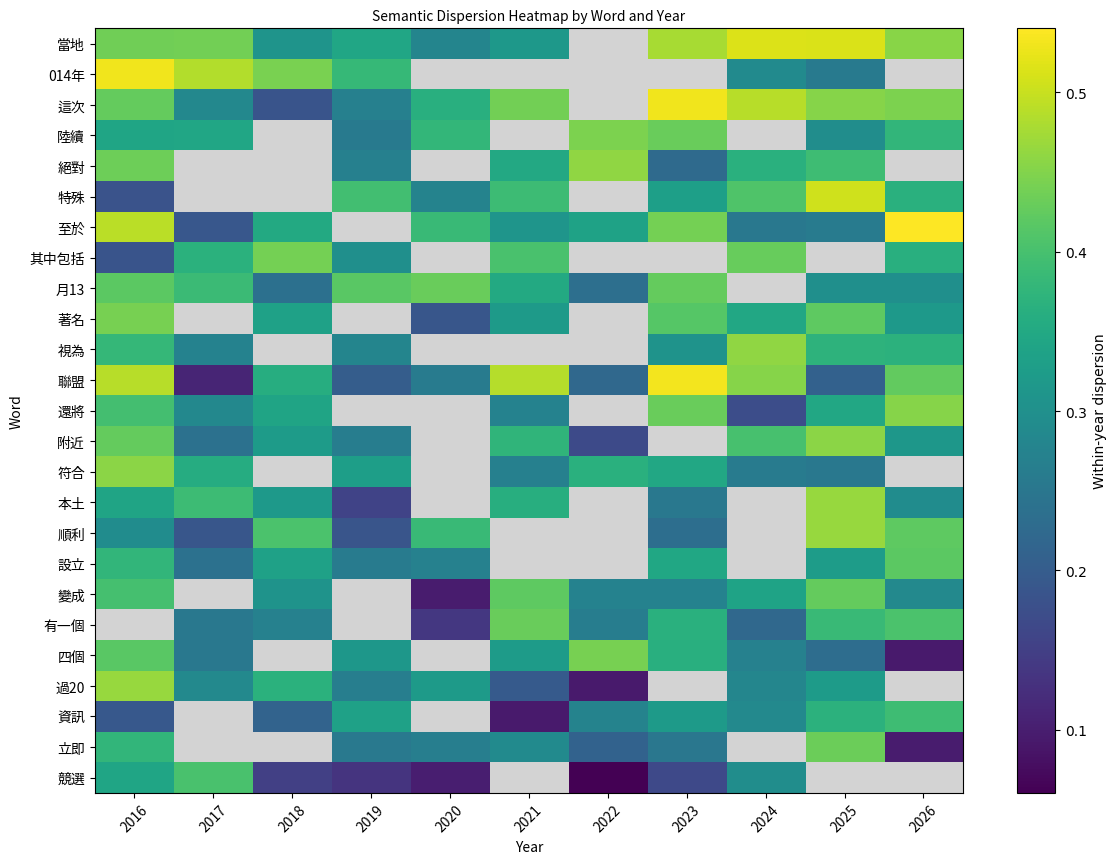

In [ ]:
# Step 2 — 改进版 Heatmap：只保留年份覆盖较好的词

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. 先筛选更稳定的词
candidate_words = summary_df[
    (summary_df["context_n"] >= 30) &
    (summary_df["year_count"] >= 5)
].copy()

top_words = candidate_words.sort_values(
    ["avg_yearly_shift", "context_n"],
    ascending=[False, False]
).head(25)["word"].tolist()

sub_year = year_df[year_df["word"].isin(top_words)].copy()

# 2. 构造 heatmap 数据
heatmap_data = sub_year.pivot_table(
    index="word",
    columns="year",
    values="within_year_dispersion",
    aggfunc="mean"
)

# 3. 删除缺失太多的词
min_years = 5
heatmap_data = heatmap_data[
    heatmap_data.notna().sum(axis=1) >= min_years
]

# 4. 按平均离散度排序
heatmap_data["mean_dispersion"] = heatmap_data.mean(axis=1)
heatmap_data = heatmap_data.sort_values("mean_dispersion", ascending=False)
heatmap_data = heatmap_data.drop(columns=["mean_dispersion"])

# 5. 用 masked array 处理缺失值
masked_data = np.ma.masked_invalid(heatmap_data.values)

cmap = plt.cm.viridis.copy()
cmap.set_bad(color="lightgrey")

plt.figure(figsize=(12, max(6, len(heatmap_data) * 0.35)))
plt.imshow(masked_data, aspect="auto", cmap=cmap)

plt.colorbar(label="Within-year dispersion")

plt.xticks(
    ticks=np.arange(len(heatmap_data.columns)),
    labels=heatmap_data.columns,
    rotation=45,
    fontproperties=font_prop
)

plt.yticks(
    ticks=np.arange(len(heatmap_data.index)),
    labels=heatmap_data.index,
    fontproperties=font_prop
)

plt.title(
    "Semantic Dispersion Heatmap by Word and Year",
    fontproperties=font_prop
)
plt.xlabel("Year", fontproperties=font_prop)
plt.ylabel("Word", fontproperties=font_prop)

plt.tight_layout()
plt.show()

用于 heatmap 的词：
['立即', '附近', '著名', '變成', '競選', '設立', '視為', '符合', '有一個', '本土', '四個', '還將', '至於', '陸續', '當地', '順利', '絕對', '特殊', '其中包括', '資訊', '聯盟', '這次', '斯坦', '中包括', '登上']


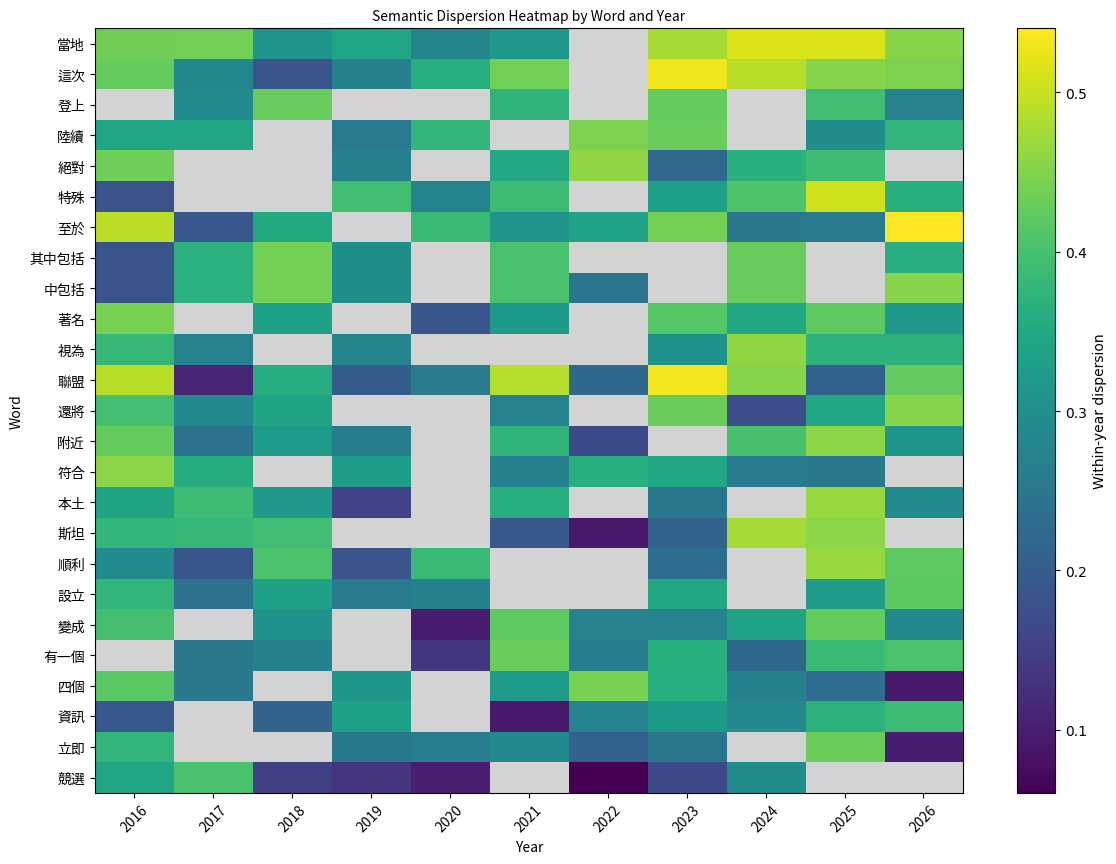

In [ ]:
#改进后的代码：

# ============================================================
# 改进版 Semantic Dispersion Heatmap
# 只保留年份覆盖较好 + 形式合理的词
# ============================================================

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import rcParams

# ------------------------------------------------------------
# 1. 字体设置
# ------------------------------------------------------------

font_path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
font_prop = fm.FontProperties(fname=font_path)

rcParams["font.family"] = font_prop.get_name()
rcParams["axes.unicode_minus"] = False


# ------------------------------------------------------------
# 2. 读取语义分析结果
# ------------------------------------------------------------

summary_df = pd.read_csv("/content/semantic_summary_cantonese.csv")
year_df = pd.read_csv("/content/semantic_shift_by_year_cantonese.csv")


# ------------------------------------------------------------
# 3. 过滤不适合画图的词
# ------------------------------------------------------------

def is_good_plot_word(w):
    w = str(w).strip()

    if not w:
        return False

    # 排除纯数字
    if re.fullmatch(r"[0-9]+", w):
        return False

    # 排除年份/日期残片：014年, 019年, 2024年, 12月, 月13
    if re.fullmatch(r"[0-9]{1,4}年", w):
        return False

    if re.fullmatch(r"[0-9]{1,2}月", w):
        return False

    if re.fullmatch(r"月[0-9]{1,2}", w):
        return False

    # 排除包含数字但不是中英混合新词的残片：過20, 至20, 20日
    if re.search(r"[0-9]", w) and not re.search(r"[A-Za-z]", w):
        return False

    # 排除明显英文碎片：BC 之外一般不画纯英文缩写 heatmap
    # 如果你想保留 AI/COVID/KOL，可以删掉这一段
    if re.fullmatch(r"[A-Za-z]+", w):
        if w not in {"AI", "COVID", "KOL", "NFT", "Web3"}:
            return False

    # 中文词：2–6字
    if re.fullmatch(r"[\u4e00-\u9fff]{2,6}", w):
        return True

    # 英文/数字 + 中文：AI生成, Web3經濟, COVID疫情
    if re.fullmatch(r"[A-Za-z0-9]{2,15}[\u4e00-\u9fff]{1,4}", w):
        return True

    # 中文 + 英文/数字：生成AI, 港版NFT
    if re.fullmatch(r"[\u4e00-\u9fff]{1,4}[A-Za-z0-9]{2,15}", w):
        return True

    # 白名单英文缩写
    if w in {"AI", "COVID", "KOL", "NFT", "Web3"}:
        return True

    return False


# ------------------------------------------------------------
# 4. 选择适合画 heatmap 的词
# ------------------------------------------------------------

candidate_words = summary_df[
    (summary_df["context_n"] >= 30) &
    (summary_df["year_count"] >= 5) &
    (summary_df["word"].apply(is_good_plot_word))
].copy()

top_words = candidate_words.sort_values(
    ["avg_yearly_shift", "context_n"],
    ascending=[False, False]
).head(25)["word"].tolist()

print("用于 heatmap 的词：")
print(top_words)


# ------------------------------------------------------------
# 5. 构造 heatmap 数据
# ------------------------------------------------------------

sub_year = year_df[year_df["word"].isin(top_words)].copy()

heatmap_data = sub_year.pivot_table(
    index="word",
    columns="year",
    values="within_year_dispersion",
    aggfunc="mean"
)

# 删除年份覆盖太少的词
min_years = 5
heatmap_data = heatmap_data[
    heatmap_data.notna().sum(axis=1) >= min_years
]

# 按平均离散度排序
heatmap_data["mean_dispersion"] = heatmap_data.mean(axis=1)
heatmap_data = heatmap_data.sort_values(
    "mean_dispersion",
    ascending=False
)
heatmap_data = heatmap_data.drop(columns=["mean_dispersion"])


# ------------------------------------------------------------
# 6. 画图
# ------------------------------------------------------------

masked_data = np.ma.masked_invalid(heatmap_data.values)

cmap = plt.cm.viridis.copy()
cmap.set_bad(color="lightgrey")

plt.figure(figsize=(12, max(6, len(heatmap_data) * 0.35)))

plt.imshow(
    masked_data,
    aspect="auto",
    cmap=cmap
)

plt.colorbar(label="Within-year dispersion")

plt.xticks(
    ticks=np.arange(len(heatmap_data.columns)),
    labels=heatmap_data.columns.astype(int),
    rotation=45,
    fontproperties=font_prop
)

plt.yticks(
    ticks=np.arange(len(heatmap_data.index)),
    labels=heatmap_data.index,
    fontproperties=font_prop
)

plt.title(
    "Semantic Dispersion Heatmap by Word and Year",
    fontproperties=font_prop
)

plt.xlabel("Year", fontproperties=font_prop)
plt.ylabel("Word", fontproperties=font_prop)

plt.tight_layout()
plt.show()

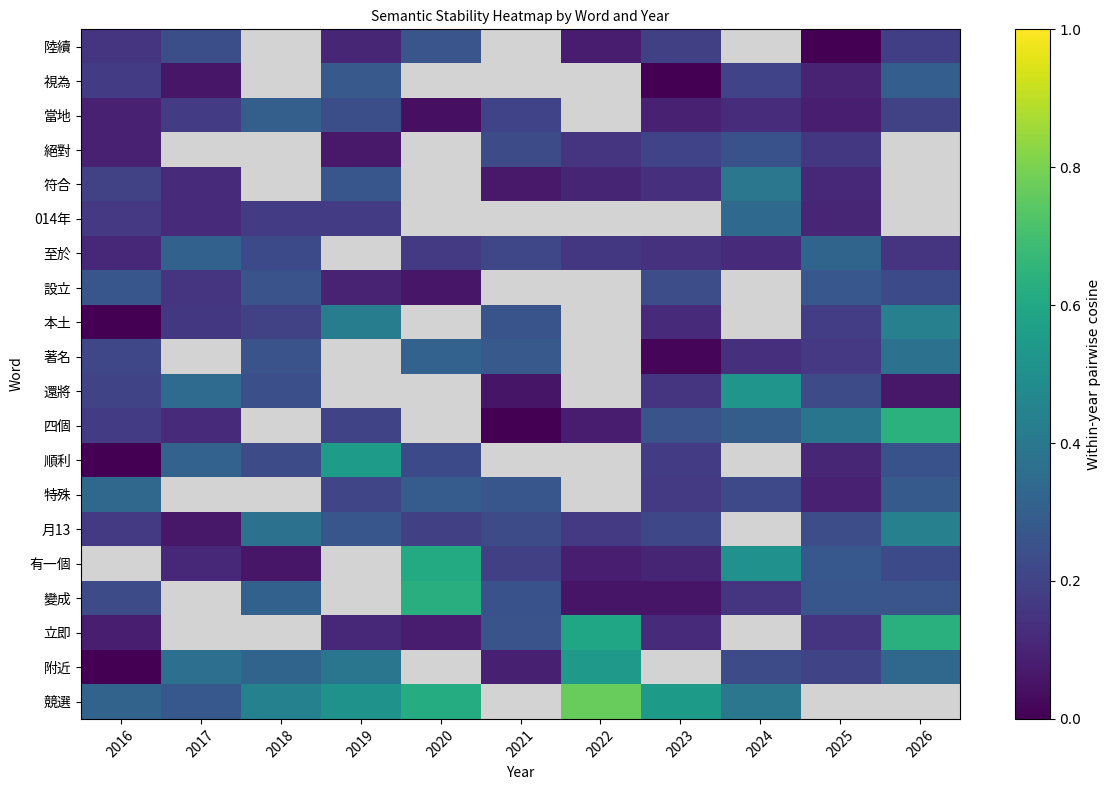

In [ ]:
# Step 3 — 改进版 Heatmap 2：语义稳定性图

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

OUT_SUMMARY = "/content/semantic_summary_cantonese.csv"
OUT_YEARLY = "/content/semantic_shift_by_year_cantonese.csv"
OUT_CONTEXTS = "/content/semantic_contexts_cantonese.csv"

summary_df = pd.read_csv(OUT_SUMMARY)
year_df = pd.read_csv(OUT_YEARLY)
context_df = pd.read_csv(OUT_CONTEXTS)

# 去掉英文缩写、功能词、过于普通的词
bad_words = {
    "認為", "進行", "通過", "提供", "發生", "這些", "這一", "自己",
    "目前", "過去", "部分", "重要", "最大", "第二", "每次",
    "有20", "30分", "除此", "除此之外", "除此之", "此之外"
}

summary_df = summary_df[
    ~summary_df["word"].str.fullmatch(r"[A-Z]{2,10}", na=False)
].copy()

year_df = year_df[
    ~year_df["word"].str.fullmatch(r"[A-Z]{2,10}", na=False)
].copy()

summary_df = summary_df[~summary_df["word"].isin(bad_words)].copy()
year_df = year_df[~year_df["word"].isin(bad_words)].copy()

# 只保留真正有跨年观察价值的词
candidate_words = summary_df[
    (summary_df["context_n"] >= 30) &
    (summary_df["year_count"] >= 5) &
    (summary_df["avg_yearly_shift"] >= 0.20)
].copy()

top_words = candidate_words.sort_values(
    ["avg_yearly_shift", "context_n"],
    ascending=[False, False]
).head(20)["word"].tolist()

sub_year = year_df[year_df["word"].isin(top_words)].copy()

heatmap_data = sub_year.pivot_table(
    index="word",
    columns="year",
    values="within_year_pairwise_cosine",
    aggfunc="mean"
)

# 删除年份太少的词
heatmap_data = heatmap_data[
    heatmap_data.notna().sum(axis=1) >= 5
]

# 排序：越不稳定越靠上
heatmap_data["mean_sim"] = heatmap_data.mean(axis=1)
heatmap_data = heatmap_data.sort_values("mean_sim", ascending=True)
heatmap_data = heatmap_data.drop(columns=["mean_sim"])

masked_data = np.ma.masked_invalid(heatmap_data.values)

cmap = plt.cm.viridis.copy()
cmap.set_bad(color="lightgrey")

plt.figure(figsize=(12, max(6, len(heatmap_data) * 0.4)))
plt.imshow(masked_data, aspect="auto", cmap=cmap, vmin=0, vmax=1)

plt.colorbar(label="Within-year pairwise cosine")

plt.xticks(
    ticks=np.arange(len(heatmap_data.columns)),
    labels=heatmap_data.columns,
    rotation=45,
    fontproperties=font_prop
)

plt.yticks(
    ticks=np.arange(len(heatmap_data.index)),
    labels=heatmap_data.index,
    fontproperties=font_prop
)

plt.title("Semantic Stability Heatmap by Word and Year", fontproperties=font_prop)
plt.xlabel("Year", fontproperties=font_prop)
plt.ylabel("Word", fontproperties=font_prop)

plt.tight_layout()
plt.show()

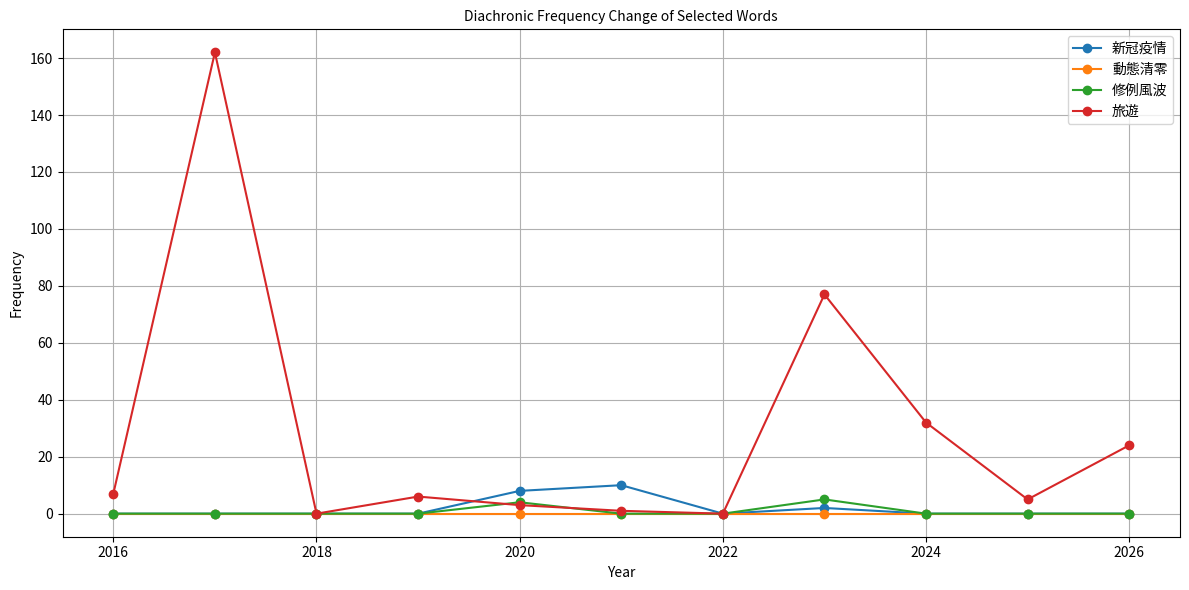

In [ ]:
#Step 4 — 频率历时图

corpus = pd.read_csv("/content/merged_all_news_tokenized.csv")
corpus["content"] = corpus["content"].fillna("").astype(str)
corpus["year"] = pd.to_datetime(corpus["date"], errors="coerce").dt.year

target_words = [
    "新冠疫情",
    "動態清零",
    "修例風波",
    "旅遊"
]

plt.figure(figsize=(12, 6))

for target_word in target_words:
    rows = []

    for _, r in corpus.iterrows():
        text = str(r["content"])
        year = r["year"]

        if pd.isna(year):
            continue

        rows.append({
            "year": int(year),
            "freq": text.count(target_word)
        })

    freq_df = (
        pd.DataFrame(rows)
        .groupby("year", as_index=False)["freq"]
        .sum()
        .sort_values("year")
    )

    plt.plot(
        freq_df["year"],
        freq_df["freq"],
        marker="o",
        label=target_word
    )

plt.title("Diachronic Frequency Change of Selected Words", fontproperties=font_prop)
plt.xlabel("Year", fontproperties=font_prop)
plt.ylabel("Frequency", fontproperties=font_prop)
plt.xticks(fontproperties=font_prop)
plt.yticks(fontproperties=font_prop)
plt.legend(prop=font_prop)
plt.grid(True)
plt.tight_layout()
plt.show()

##另一种

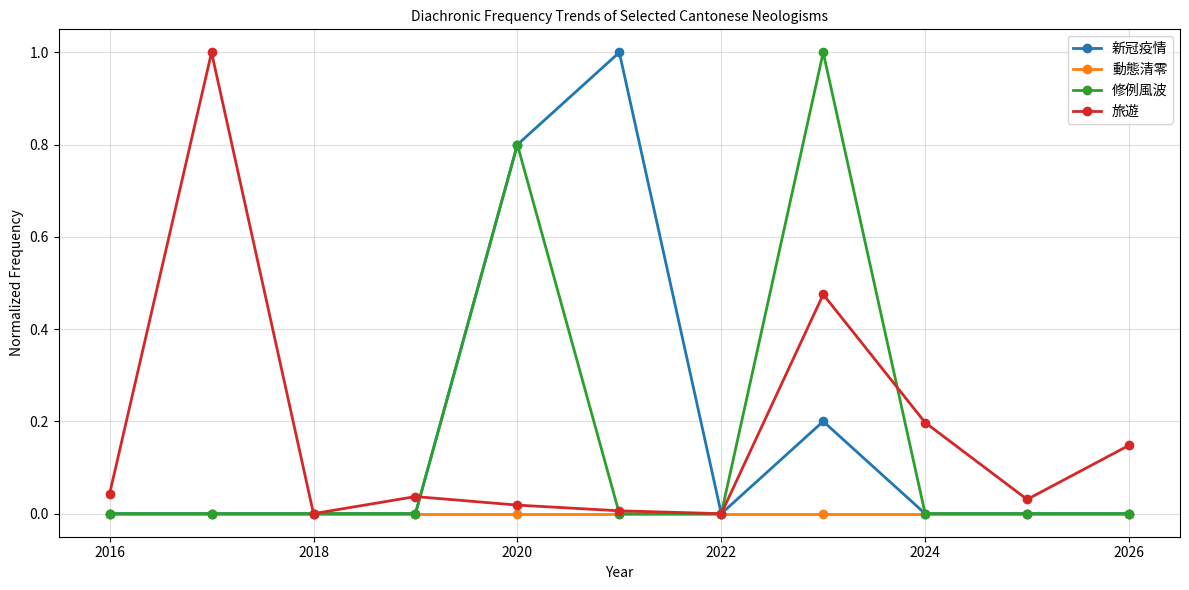

In [ ]:
# Step 4 — 频率历时图：归一化版本

import pandas as pd
import matplotlib.pyplot as plt

corpus = pd.read_csv("/content/merged_all_news_tokenized.csv")

corpus["content"] = corpus["content"].fillna("").astype(str)
corpus["year"] = pd.to_datetime(corpus["date"], errors="coerce").dt.year

target_words = [
    "新冠疫情",
    "動態清零",
    "修例風波",
    "旅遊"
]

plt.figure(figsize=(12, 6))

for target_word in target_words:
    rows = []

    for _, r in corpus.iterrows():
        text = str(r["content"])
        year = r["year"]

        if pd.isna(year):
            continue

        rows.append({
            "year": int(year),
            "freq": text.count(target_word)
        })

    freq_df = (
        pd.DataFrame(rows)
        .groupby("year", as_index=False)["freq"]
        .sum()
        .sort_values("year")
    )

    if freq_df["freq"].max() > 0:
        freq_df["norm_freq"] = freq_df["freq"] / freq_df["freq"].max()
    else:
        freq_df["norm_freq"] = 0

    plt.plot(
        freq_df["year"],
        freq_df["norm_freq"],
        marker="o",
        linewidth=2,
        label=target_word
    )

plt.title(
    "Diachronic Frequency Trends of Selected Cantonese Neologisms",
    fontproperties=font_prop
)
plt.xlabel("Year", fontproperties=font_prop)
plt.ylabel("Normalized Frequency", fontproperties=font_prop)

plt.xticks(fontproperties=font_prop)
plt.yticks(fontproperties=font_prop)

plt.legend(prop=font_prop)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

#另一种2

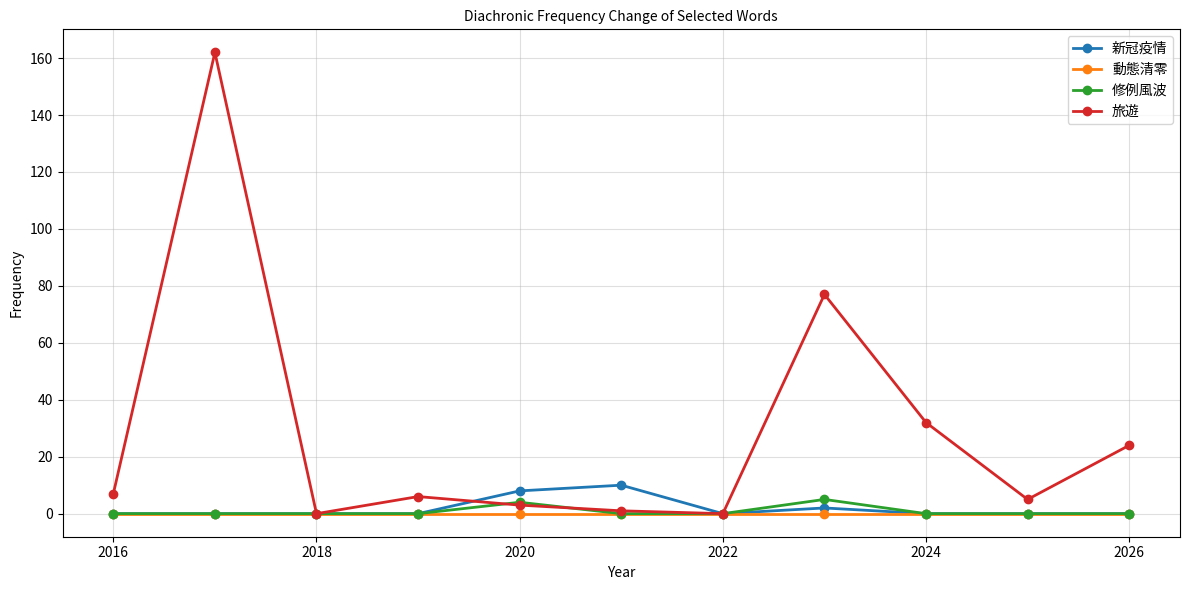

In [ ]:
# Step 4 bis — 频率历时图：绝对频数版本

import pandas as pd
import matplotlib.pyplot as plt

corpus = pd.read_csv("/content/merged_all_news_tokenized.csv")

corpus["content"] = corpus["content"].fillna("").astype(str)
corpus["year"] = pd.to_datetime(corpus["date"], errors="coerce").dt.year

target_words = [
    "新冠疫情",
    "動態清零",
    "修例風波",
    "旅遊"
]

plt.figure(figsize=(12, 6))

for target_word in target_words:
    rows = []

    for _, r in corpus.iterrows():
        text = str(r["content"])
        year = r["year"]

        if pd.isna(year):
            continue

        rows.append({
            "year": int(year),
            "freq": text.count(target_word)
        })

    freq_df = (
        pd.DataFrame(rows)
        .groupby("year", as_index=False)["freq"]
        .sum()
        .sort_values("year")
    )

    plt.plot(
        freq_df["year"],
        freq_df["freq"],
        marker="o",
        linewidth=2,
        label=target_word
    )

plt.title(
    "Diachronic Frequency Change of Selected Words",
    fontproperties=font_prop
)
plt.xlabel("Year", fontproperties=font_prop)
plt.ylabel("Frequency", fontproperties=font_prop)

plt.xticks(fontproperties=font_prop)
plt.yticks(fontproperties=font_prop)

plt.legend(prop=font_prop)
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

找到记录数: 7


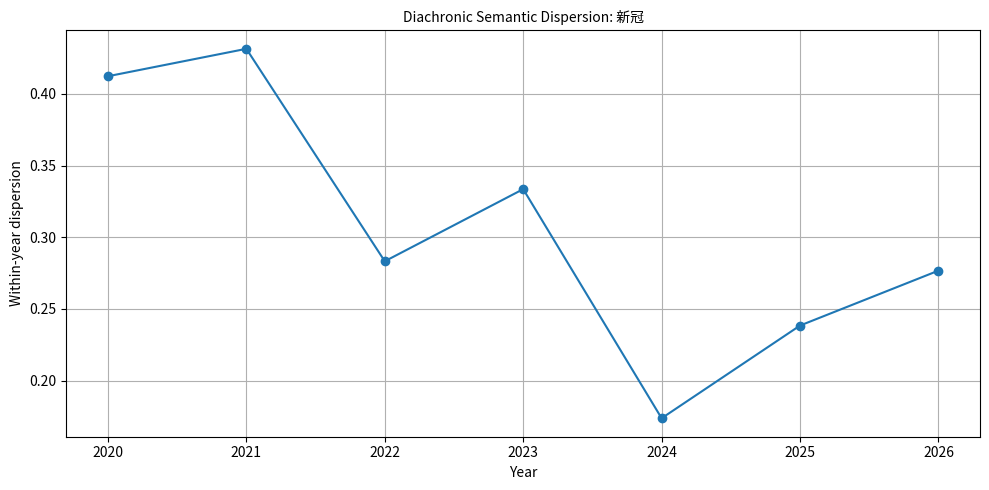

In [ ]:
#Step 5 — 单个词语义离散度图

target_word = "新冠"

sub = year_df[year_df["word"] == target_word].sort_values("year")

print("找到记录数:", len(sub))

if sub.empty:
    print(f"没有找到词: {target_word}")
else:
    plt.figure(figsize=(10, 5))
    plt.plot(sub["year"], sub["within_year_dispersion"], marker="o")

    plt.title(f"Diachronic Semantic Dispersion: {target_word}", fontproperties=font_prop)
    plt.xlabel("Year", fontproperties=font_prop)
    plt.ylabel("Within-year dispersion", fontproperties=font_prop)

    plt.xticks(fontproperties=font_prop)
    plt.yticks(fontproperties=font_prop)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
#或者先运行看看有哪些词

print(year_df["word"].nunique())

words = (
    year_df.groupby("word")
    .size()
    .sort_values(ascending=False)
)

print(words.head(100))

4362
word
空間    11
穩定    11
積極    11
程度    11
兩個    11
      ..
汽車    11
決定    11
處於    11
萬人    11
水平    11
Length: 100, dtype: int64


In [ ]:
#以上例子说明我们找的是高频词而不是新词，先看看以下， 先看看真正的高频词

summary_df.sort_values(
    "context_n",
    ascending=False
)[[
    "word",
    "context_n",
    "year_count",
    "avg_yearly_shift"
]].head(50)

,word,context_n,year_count,avg_yearly_shift
0,一個,220,11,0.267916
2,個月,139,11,0.347682
3069,億美,137,11,0.246955
3,聯合,134,11,0.399682
4,綜合,132,11,0.281645
5,進一,132,11,0.278110
3072,預測,131,11,0.245269
6,月份,131,11,0.394186
3071,面臨,131,11,0.249856
3070,會議,131,11,0.250042


In [ ]:
#找真正有语义变化的词
summary_df.sort_values(
    "avg_yearly_shift",
    ascending=False
)[[
    "word",
    "avg_yearly_shift",
    "context_n",
    "year_count"
]].head(100)

,word,avg_yearly_shift,context_n,year_count
2682,聯絡,0.973753,10,7
1358,臨時,0.961556,17,9
2436,為第一,0.938236,11,7
2878,996,0.921761,9,5
1930,直至,0.916042,13,8
...,...,...,...,...
1925,此後,0.770066,13,10
1380,隨時,0.769778,17,8
2186,滿意,0.769008,12,7
1972,也成為,0.768370,13,7


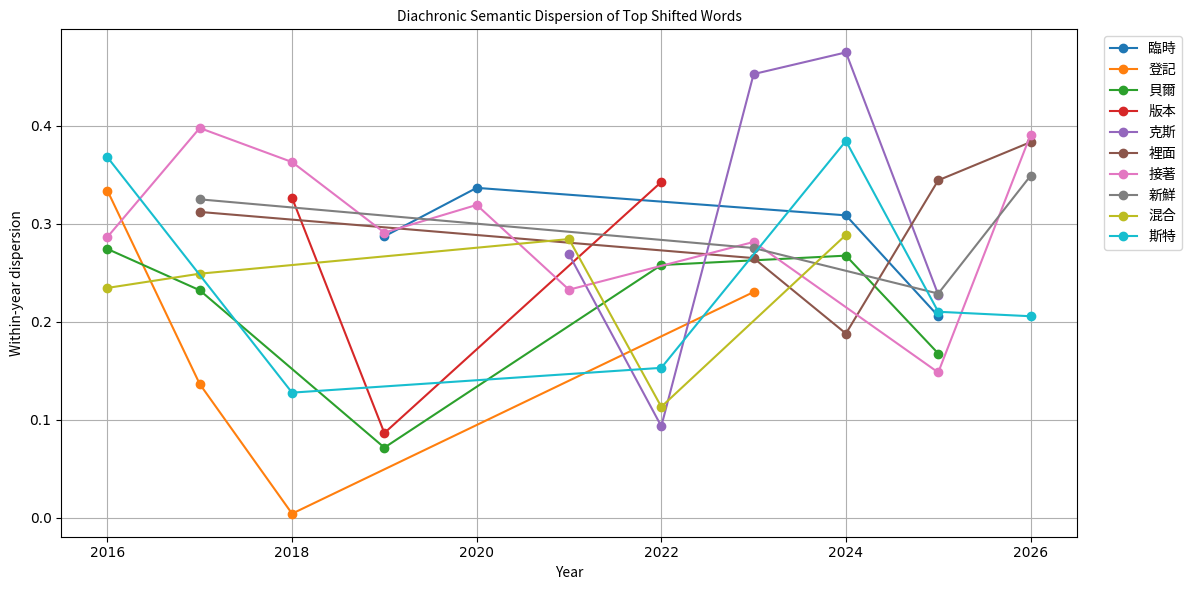

In [ ]:
#Step 6 — 多词语义变化图

top_words = (
    summary_df[summary_df["context_n"] >= 15]
    .sort_values("avg_yearly_shift", ascending=False)
    .head(10)["word"]
    .tolist()
)

plt.figure(figsize=(12, 6))

for word in top_words:
    sub = year_df[year_df["word"] == word].sort_values("year")

    if len(sub) >= 2:
        plt.plot(
            sub["year"],
            sub["within_year_dispersion"],
            marker="o",
            label=word
        )

plt.title("Diachronic Semantic Dispersion of Top Shifted Words", fontproperties=font_prop)
plt.xlabel("Year", fontproperties=font_prop)
plt.ylabel("Within-year dispersion", fontproperties=font_prop)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    prop=font_prop
)

plt.grid(True)
plt.tight_layout()
plt.show()

找到记录数: 6
     word  year  context_n_year  shift_from_previous_year
1666   新冠  2021              20                  0.127587
1667   新冠  2022               3                  0.455809
1668   新冠  2023               5                  0.541491
1669   新冠  2024               3                  0.388335
1670   新冠  2025               7                  0.386475
1671   新冠  2026               7                  0.210757


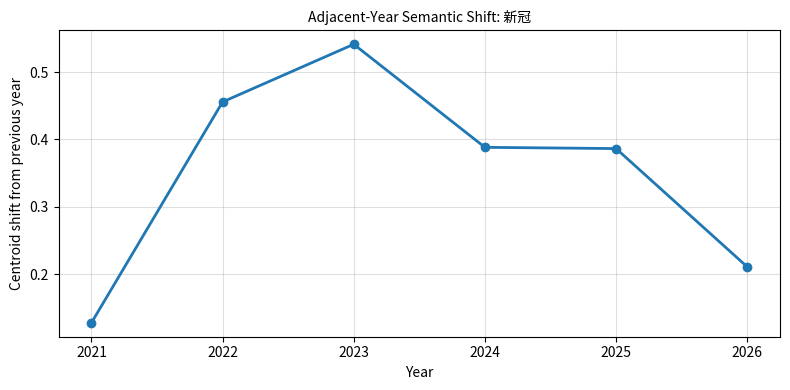

In [ ]:
# Step 7 — 相邻年份漂移图：安全版

import matplotlib.pyplot as plt
import pandas as pd

target_word = "新冠"

sub = year_df[
    (year_df["word"] == target_word) &
    (year_df["shift_from_previous_year"].notna())
].copy()

sub = sub.sort_values("year")

print("找到记录数:", len(sub))
print(sub[["word", "year", "context_n_year", "shift_from_previous_year"]])

if sub.empty:
    print(f"没有找到 {target_word} 的 shift_from_previous_year")

else:
    plt.close("all")

    fig, ax = plt.subplots(figsize=(8, 4), dpi=100)

    ax.plot(
        sub["year"],
        sub["shift_from_previous_year"],
        marker="o",
        linewidth=2
    )

    ax.set_title(
        f"Adjacent-Year Semantic Shift: {target_word}",
        fontproperties=font_prop
    )
    ax.set_xlabel("Year", fontproperties=font_prop)
    ax.set_ylabel("Centroid shift from previous year", fontproperties=font_prop)

    ax.grid(True, alpha=0.4)

    for label in ax.get_xticklabels():
        label.set_fontproperties(font_prop)

    for label in ax.get_yticklabels():
        label.set_fontproperties(font_prop)

    fig.tight_layout()
    plt.show()

找到记录数: 11


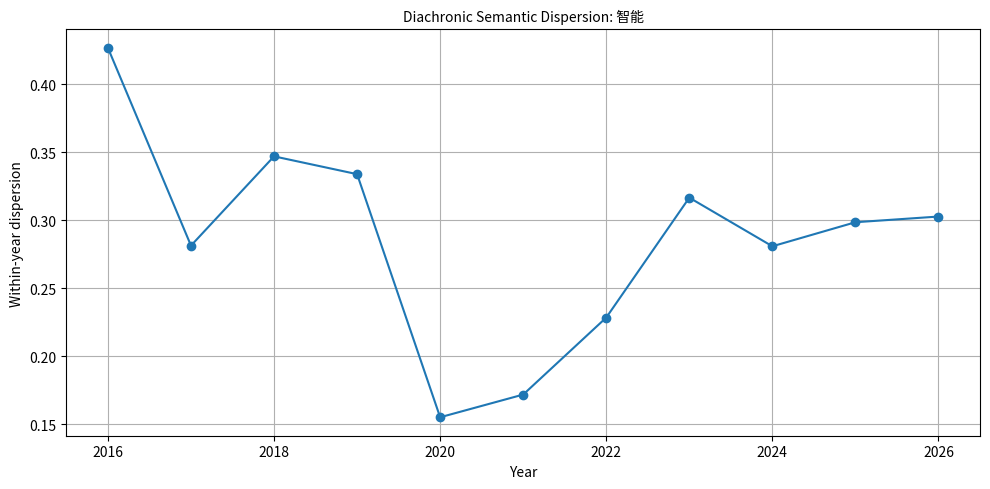

In [ ]:
target_word = "智能"

sub = year_df[year_df["word"] == target_word].sort_values("year")

print("找到记录数:", len(sub))

if sub.empty:
    print(f"没有找到词: {target_word}")
else:
    plt.figure(figsize=(10, 5))
    plt.plot(sub["year"], sub["within_year_dispersion"], marker="o")

    plt.title(f"Diachronic Semantic Dispersion: {target_word}",
              fontproperties=font_prop)

    plt.xlabel("Year", fontproperties=font_prop)
    plt.ylabel("Within-year dispersion", fontproperties=font_prop)

    plt.xticks(fontproperties=font_prop)
    plt.yticks(fontproperties=font_prop)

    plt.grid(True)
    plt.tight_layout()
    plt.show()

找到记录数: 9


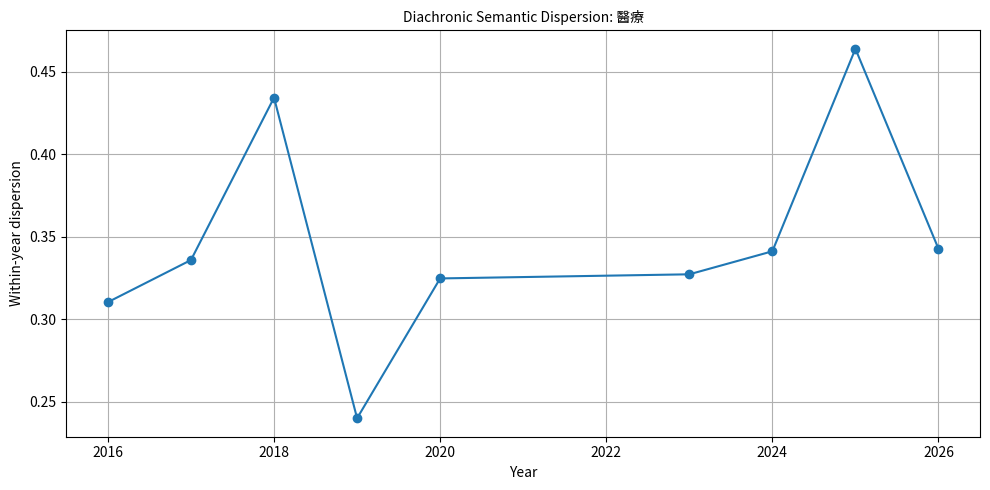

In [ ]:
target_word = "醫療"

sub = year_df[year_df["word"] == target_word].sort_values("year")

print("找到记录数:", len(sub))

if sub.empty:
    print(f"没有找到词: {target_word}")
else:
    plt.figure(figsize=(10, 5))
    plt.plot(sub["year"], sub["within_year_dispersion"], marker="o")

    plt.title(f"Diachronic Semantic Dispersion: {target_word}",
              fontproperties=font_prop)

    plt.xlabel("Year", fontproperties=font_prop)
    plt.ylabel("Within-year dispersion", fontproperties=font_prop)

    plt.xticks(fontproperties=font_prop)
    plt.yticks(fontproperties=font_prop)

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
!apt-get install fonts-noto-cjk -y

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto-cjk is already the newest version (1:20220127+repack1-1).
0 upgraded, 0 newly installed, 0 to remove and 40 not upgraded.


In [ ]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP']
plt.rcParams['axes.unicode_minus'] = False

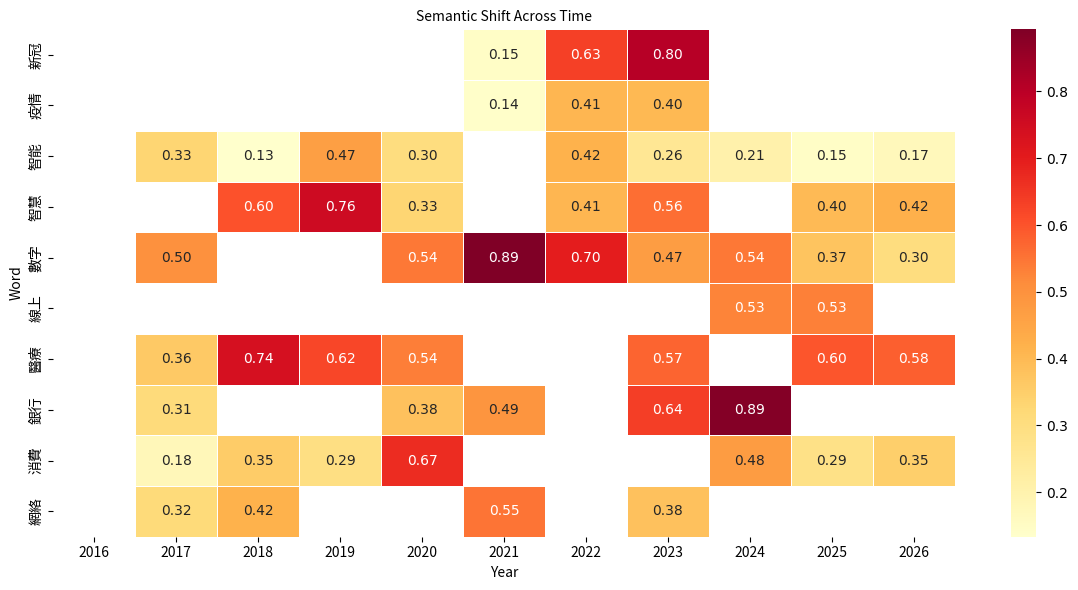

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import rcParams

# Define font path and properties for CJK characters
font_path = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
font_prop = fm.FontProperties(fname=font_path)

# Rebuild matplotlib's font cache to ensure new fonts are recognized
fm._rebuild()

# Set global font parameters
rcParams["font.family"] = font_prop.get_name()
rcParams["axes.unicode_minus"] = False

# 10个词
words = [
    "新冠",
    "疫情",
    "智能",
    "智慧",
    "數字",
    "線上",
    "醫療",
    "銀行",
    "消費",
    "網絡"
]

# 真实数据：year, context_n_year, pairwise_cosine, dispersion, shift, word
rows = [
    [2020,20,0.32121261954307556,0.4040536880493164,None,"新冠"],
    [2021,20,0.3395631015300751,0.3896026015281677,0.14690804481506348,"新冠"],
    [2022,2,0.36736083030700684,0.17315033078193665,0.6332659721374512,"新冠"],
    [2023,2,0.4332911968231201,0.15345075726509094,0.8044579029083252,"新冠"],

    [2020,20,0.29602503776550293,0.42447957396507263,None,"疫情"],
    [2021,20,0.2739541828632355,0.44299325346946716,0.14012449979782104,"疫情"],
    [2022,4,0.3189941346645355,0.3005390763282776,0.4084535241127014,"疫情"],
    [2023,9,0.24353885650634766,0.42764514684677124,0.40175342559814453,"疫情"],

    [2016,11,0.305726557970047,0.39267608523368835,None,"智能"],
    [2017,4,0.3502798080444336,0.2839624881744385,0.3298794627189636,"智能"],
    [2018,12,0.36202311515808105,0.35564926266670227,0.13322198390960693,"智能"],
    [2019,2,0.35232460498809814,0.17770922183990479,0.46601998805999756,"智能"],
    [2020,3,0.5703323483467102,0.155278280377388,0.3044799566268921,"智能"],
    [2022,4,0.460294246673584,0.2284945696592331,0.4202226400375366,"智能"],
    [2023,14,0.4124879837036133,0.3258685767650604,0.25780653953552246,"智能"],
    [2024,6,0.4115995466709137,0.2860908806324005,0.20687317848205566,"智能"],
    [2025,13,0.42166078090667725,0.3172493577003479,0.14655804634094238,"智能"],
    [2026,11,0.4795888662338257,0.27412188053131104,0.16933417320251465,"智能"],

    [2016,2,0.2746124267578125,0.20168542861938477,None,"智慧"],
    [2018,3,0.2730986177921295,0.28208696842193604,0.6047413349151611,"智慧"],
    [2019,2,0.4132809638977051,0.15938082337379456,0.757900059223175,"智慧"],
    [2020,3,0.36483755707740784,0.24068565666675568,0.33166074752807617,"智慧"],
    [2022,3,0.5436838269233704,0.16586028039455414,0.4076486825942993,"智慧"],
    [2023,2,0.5289390087127686,0.12566053867340088,0.5581004023551941,"智慧"],
    [2025,2,0.4822040796279907,0.13912707567214966,0.39809370040893555,"智慧"],
    [2026,7,0.29619157314300537,0.3701304793357849,0.4228243827819824,"智慧"],

    [2016,6,0.15597374737262726,0.455348938703537,None,"數字"],
    [2017,2,0.2141658067703247,0.22084477543830872,0.5016622543334961,"數字"],
    [2020,4,0.4837963581085205,0.21715442836284637,0.5445507764816284,"數字"],
    [2021,4,0.445746511220932,0.23559845983982086,0.8930596709251404,"數字"],
    [2022,4,0.3991432189941406,0.2588135004043579,0.6986704468727112,"數字"],
    [2023,5,0.46337857842445374,0.24455127120018005,0.47160446643829346,"數字"],
    [2024,3,0.47743210196495056,0.1927693486213684,0.5445324182510376,"數字"],
    [2025,9,0.2935054302215576,0.39007803797721863,0.374805212020874,"數字"],
    [2026,5,0.41371601819992065,0.2713211476802826,0.302578866481781,"數字"],

    [2020,7,0.4470781683921814,0.2746952176094055,None,"線上"],
    [2024,2,0.1532914638519287,0.24062812328338623,0.5250176787376404,"線上"],
    [2025,8,0.3396303355693817,0.35024890303611755,0.5325408577919006,"線上"],

    [2016,7,0.40727323293685913,0.29860958456993103,None,"醫療"],
    [2017,3,0.6975626945495605,0.10648158937692642,0.3634452819824219,"醫療"],
    [2018,2,0.280981183052063,0.1996934413909912,0.7373721599578857,"醫療"],
    [2019,2,0.37627577781677246,0.17045921087265015,0.6222975850105286,"醫療"],
    [2020,2,0.11592221260070801,0.2530321180820465,0.5356696248054504,"醫療"],
    [2023,4,0.5426077246665955,0.18947190046310425,0.5740219354629517,"醫療"],
    [2025,4,0.2244553565979004,0.3532068133354187,0.5978817939758301,"醫療"],
    [2026,5,0.35814279317855835,0.3024943172931671,0.5835906267166138,"醫療"],

    [2016,8,0.3451317250728607,0.34655505418777466,None,"銀行"],
    [2017,10,0.28003814816474915,0.4066751003265381,0.3140542507171631,"銀行"],
    [2020,3,0.3487575948238373,0.24777762591838837,0.3796640634536743,"銀行"],
    [2021,5,0.49459272623062134,0.2282007485628128,0.49261027574539185,"銀行"],
    [2023,4,0.659632682800293,0.13702575862407684,0.6370145082473755,"銀行"],
    [2024,3,0.3970073163509369,0.22669221460819244,0.8855850100517273,"銀行"],

    [2016,6,0.393431156873703,0.29677462577819824,None,"消費"],
    [2017,13,0.39952927827835083,0.3323778510093689,0.1760481595993042,"消費"],
    [2018,3,0.6059553027153015,0.14133620262145996,0.35330092906951904,"消費"],
    [2019,3,0.41762733459472656,0.2178545445203781,0.29369497299194336,"消費"],
    [2020,5,0.2167799472808838,0.3889157176017761,0.6685004234313965,"消費"],
    [2024,7,0.4396423101425171,0.2791023850440979,0.4760889410972595,"消費"],
    [2025,5,0.387439489364624,0.2858910858631134,0.28617894649505615,"消費"],
    [2026,20,0.34152501821517944,0.3880777955055237,0.3498324155807495,"消費"],

    [2016,15,0.31197935342788696,0.40179651975631714,None,"網絡"],
    [2017,4,0.2155582159757614,0.3583858609199524,0.31554168462753296,"網絡"],
    [2018,3,0.5312095284461975,0.17085999250411987,0.4186074733734131,"網絡"],
    [2021,4,0.2694495618343353,0.32762575149536133,0.5491364002227783,"網絡"],
    [2023,9,0.45224153995513916,0.2836875021457672,0.3805420398712158,"網絡"],
]

year_df = pd.DataFrame(
    rows,
    columns=[
        "year",
        "context_n_year",
        "within_year_pairwise_cosine",
        "within_year_dispersion",
        "shift_from_previous_year",
        "word"
    ]
)

# 生成 heatmap 数据
pivot_df = year_df.pivot(
    index="word",
    columns="year",
    values="shift_from_previous_year"
)

# 按你指定的词顺序排列
pivot_df = pivot_df.reindex(words)

plt.figure(figsize=(12, 6))

ax = sns.heatmap(
    pivot_df,
    cmap="YlOrRd",
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    linecolor="white"
)

# 中文字体
for label in ax.get_yticklabels():
    label.set_fontproperties(font_prop)

for label in ax.get_xticklabels():
    label.set_fontproperties(font_prop)

plt.title(
    "Semantic Shift Across Time",
    fontproperties=font_prop
)
plt.xlabel("Year", fontproperties=font_prop)
plt.ylabel("Word", fontproperties=font_prop)

plt.tight_layout()
plt.show()